# Classification by Hand
### Part 1: Logistic Regression. Part 2: KNN. Let's calculate both ourselves.

Last class the model guessed a **number**. Today the model guesses a **group** (yes/no).

We learn **two models**, one after the other. Each part has its **own data, own code and own pictures**:

| | Part 1: Logistic Regression | Part 2: KNN |
|---|---|---|
| Idea | draw a line, give a **chance** | ask the **nearest neighbours**, take a vote |
| Small data (8 rows) | 8 loan applicants | 8 fruits (lemon or orange) |
| Real data | `loans.csv` | `loans.csv` |
| Needs scaling? | no | **yes** |

In both parts we calculate on the whiteboard first. Then we do the same in code.
At the end you will see: `model.fit()` and `model.predict()` are not magic.

## CONCEPT: Regression or classification?

| | Regression | Classification (today) |
|--|------------|------------------------|
| Guesses | a **number** | a **group** |
| Example | the price of a house | approved / not approved |
| How we check it | MAE | **accuracy** = right guesses ÷ all guesses |

**Quick test:** can the answer be 112.4? → regression. Is it one of a few groups? → classification.

### ✏️ QUICK CHECK 0
Regression or classification?
1. How many marks will a student get?
2. Will a student pass or fail?
3. Is this email spam?
4. How many lakh will a house sell for?

**Answer:** 1. Regression. 2. Classification. 3. Classification. 4. Regression.

# Part 1: Logistic Regression

**Idea:** give the model a person. It gives back a **chance** from 0 to 1.
Above 0.5 → **approve**. Below 0.5 → **reject**.

| Word | Meaning |
|------|---------|
| **Score z** | a number from a line formula |
| **Sigmoid** | a formula that turns any score into a chance from 0 to 1 |
| **Probability** | a chance from 0 to 1. 0.8 means 80% |
| **Threshold** | where we decide. Usually 0.5 |

## The data: 8 loan applicants

| Person | Monthly income (thousand Rs) | Years in job | Approved? (1 = yes) |
|---|---|---|---|
| A | 80 | 1 | 0 |
| B | 100 | 7 | 0 |
| C | 50 | 3 | 0 |
| D | 90 | 2 | 0 |
| E | 150 | 2 | 1 |
| F | 40 | 9 | 1 |
| G | 110 | 10 | 1 |
| H | 180 | 6 | 1 |

**Question:** a new person has income **100** and **8 years** in the job. What is the **chance** that the bank approves?

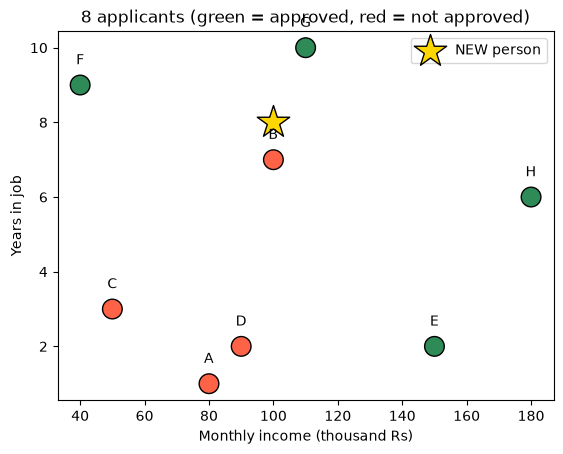

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

people = pd.DataFrame({
    "monthly_income": [80, 100, 50, 90, 150, 40, 110, 180],
    "years_in_job":   [1, 7, 3, 2, 2, 9, 10, 6],
    "approved":       [0, 0, 0, 0, 1, 1, 1, 1],
}, index=list("ABCDEFGH"))
new_person = pd.DataFrame({"monthly_income": [100], "years_in_job": [8]})

colours = people["approved"].map({0: "tomato", 1: "seagreen"})
plt.scatter(people["monthly_income"], people["years_in_job"], c=colours, s=200, edgecolors="black")
for name, row in people.iterrows():
    plt.annotate(name, (row["monthly_income"], row["years_in_job"]), xytext=(0, 15), textcoords="offset points", ha="center")
plt.scatter(100, 8, marker="*", s=600, color="gold", edgecolors="black", label="NEW person")
plt.xlabel("Monthly income (thousand Rs)")
plt.ylabel("Years in job")
plt.title("8 applicants (green = approved, red = not approved)")
plt.legend()
plt.show()



## CONCEPT: Two steps, score then chance

**Step A: a score z** (a line formula, like Linear Regression)

$$z = \beta_0 + \beta_1 \times \text{income} + \beta_2 \times \text{years}$$

A bigger z means "more likely approved". But z can be any number: −50 or 400. A chance must be between 0 and 1.

**Step B: the sigmoid** squashes z into a chance:

$$\text{chance} = \frac{1}{1 + e^{-z}}$$

($e$ is about 2.718. Your calculator has an `e^x` button.)

| z | e^(−z) | 1 + e^(−z) | chance | Meaning |
|---|---|---|---|---|
| −4 | 54.6 | 55.6 | **0.02** | almost sure: no |
| −2 | 7.39 | 8.39 | **0.12** | probably no |
| 0 | 1 | 2 | **0.50** | 50/50: the border |
| 2 | 0.135 | 1.135 | **0.88** | probably yes |
| 4 | 0.018 | 1.018 | **0.98** | almost sure: yes |

Then the rule: chance **above 0.5** (which means z above 0) → **approve**.

In [ ]:
z_values = np.array([-4, -2, 0, 2, 4])
chance = 1 / (1 + np.exp(-z_values))
pd.DataFrame({"z": z_values, "chance": chance.round(2)})

## Step 1: The model learns 3 numbers. We do the 2 steps ourselves.

`fit()` finds the best β0, β1, β2 (the maths is called *maximum likelihood*. We skip it today).
We read them, then calculate the chance for our new person.

In [ ]:
from sklearn.linear_model import LogisticRegression

features = ["monthly_income", "years_in_job"]
log_model = LogisticRegression()
log_model.fit(people[features], people["approved"])

b0 = log_model.intercept_[0]
b_income, b_years = log_model.coef_[0]
print("β0 (intercept):", round(b0, 2))
print("β1 (income):   ", round(b_income, 3))
print("β2 (years):    ", round(b_years, 3))

# Step A: the score z (multiply and add, like Linear Regression)
z = b0 + b_income * 100 + b_years * 8
print("\nz = ", round(b0, 2), "+", round(b_income, 3), "× 100 +", round(b_years, 3), "× 8")
print("z =", round(z, 2))

# Step B: the sigmoid
chance_by_hand = 1 / (1 + np.exp(-z))
print("\nchance by hand     :", round(chance_by_hand, 2))
print("model.predict_proba:", round(log_model.predict_proba(new_person)[0, 1], 2))

**Same number: 0.82.** So the model says **APPROVE** (0.82 is above 0.5).

`predict_proba` is only these 2 steps: **score z → sigmoid → chance**.

**What the βs tell us:**
- β2 (years) is **0.49**. β1 (income) is **0.034**. One extra year in the job pushes z as much as about **14 thousand** more income.
- A positive β pushes the chance **up**. A negative β would push it **down**.

## Step 2: See it (two pictures)

- **Left:** the border where z = 0 (chance exactly 0.5). Above the line → approve. Below → reject.
- **Right:** the sigmoid. Our new person sits at z = 1.52, chance 0.82.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: the border is where z = 0
ax[0].scatter(people["monthly_income"], people["years_in_job"], c=colours, s=200, edgecolors="black")
incomes = np.array([30, 190])
border_years = -(b0 + b_income * incomes) / b_years         # z = 0, solved for years
ax[0].plot(incomes, border_years, color="black", linestyle="--", label="border: z = 0, chance 0.5")
ax[0].scatter(100, 8, marker="*", s=600, color="gold", edgecolors="black", label="NEW person")
ax[0].set_xlim(30, 190)
ax[0].set_ylim(0, 11)
ax[0].set_xlabel("Monthly income (thousand Rs)")
ax[0].set_ylabel("Years in job")
ax[0].set_title("The border: above = approve, below = reject")
ax[0].legend()

# Right: the sigmoid, with our new person on it
zz = np.linspace(-6, 6, 200)
ax[1].plot(zz, 1 / (1 + np.exp(-zz)), color="black", linewidth=3)
ax[1].axhline(0.5, color="gray", linestyle="--")
ax[1].axvline(0, color="gray", linestyle="--")
ax[1].scatter(z, chance_by_hand, marker="*", s=600, color="gold", edgecolors="black", zorder=3, label="NEW person")
ax[1].set_xlabel("score z")
ax[1].set_ylabel("chance of approval")
ax[1].set_title("The sigmoid: z = " + str(round(z, 2)) + " gives chance " + str(round(chance_by_hand, 2)))
ax[1].legend()
plt.show()

**Look at the left picture:** the line is **not perfect**. B (red) is above the line and F (green) is below it, so the model gets them wrong. A straight line cannot be perfect on messy data. That is normal.

### ✏️ QUICK CHECK 1
A person has income **50** and **3 years** in the job (this is person C). Calculate z and the chance by hand. What does the model say?

**Answer:** z = −5.80 + 0.034 × 50 + 0.487 × 3 = **−2.63**. Chance = 1 ÷ (1 + e^2.63) = **0.07**. That is below 0.5 → **REJECT**.

## Step 3: The real file: 400 loan applications

8 people is too few to test. We only wanted to see **how the model decides**.

- **Train** (80%): the model learns from these.
- **Test** (20%): hidden. We check the model on them.
- `stratify=y` keeps the same mix of yes/no in train and test.

**Using Colab?** Upload `loans.csv` first.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", len(X_train), " Test:", len(X_test))

log_loans = LogisticRegression(max_iter=1000).fit(X_train, y_train)

# Accuracy by hand: right guesses ÷ all guesses
guess = log_loans.predict(X_test)
right = (guess == y_test).sum()
print("By hand :", right, "right out of", len(y_test), "=", right / len(y_test))
print("sklearn :", accuracy_score(y_test, guess))

# A new applicant
person = pd.DataFrame({"monthly_income": [120000], "loan_amount": [10], "years_in_job": [6], "has_defaulted_before": [0]})
chance = log_loans.predict_proba(person)[0, 1]
print("\nNew applicant: chance of approval =", round(chance, 2), "->", "APPROVE" if chance >= 0.5 else "REJECT")

Logistic Regression was right for about **86 out of 100** new applications. It also gives a **chance**, so the manager can check the unclear cases (for example 40% to 60%) by hand.

Notice: we did **not** scale anything. Logistic Regression learns one β for each column, so big or small numbers are fine.

### ✏️ QUICK CHECK 2
A new applicant gets a chance of **0.45**. What does the model say? Should the manager trust it?

**Answer:** **Reject**, because 0.45 is below 0.5. But 0.45 is close to the middle, so it is a **hard case**. A human should look at it.

# Part 2: KNN (K-Nearest Neighbours)

**Idea:** give the model a new example. It finds the **k most similar** past examples and takes a **vote**.

New data set, new problem, so we start fresh. Nothing from Part 1 is used here.

| Word | Meaning |
|------|---------|
| **Distance** | how far two examples are from each other |
| **k** | how many neighbours vote |
| **Scaling** | putting all columns on the same size |
| **Mean, std** | the middle of a column, and how spread out it is |
| **z-score** | a scaled number: (x − mean) ÷ std |

## The data: 8 fruits (lemon or orange?)

| Fruit | Weight (g) | Sweetness (0 = sour, 10 = sweet) | Type |
|---|---|---|---|
| A | 110 | 2 | lemon (0) |
| B | 120 | 3 | lemon (0) |
| C | 130 | 2 | lemon (0) |
| D | 140 | 3 | lemon (0) |
| E | 125 | 8 | orange (1) |
| F | 150 | 7 | orange (1) |
| G | 170 | 7 | orange (1) |
| H | 175 | 8 | orange (1) |

**Question:** a new fruit weighs **135 g** and has sweetness **6**. Is it a lemon or an orange?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fruit = pd.DataFrame({
    "weight_g":  [110, 120, 130, 140, 125, 150, 170, 175],
    "sweetness": [2, 3, 2, 3, 8, 7, 7, 8],
    "is_orange": [0, 0, 0, 0, 1, 1, 1, 1],
}, index=list("ABCDEFGH"))
new_fruit = pd.DataFrame({"weight_g": [135], "sweetness": [6]})

fruit_colours = fruit["is_orange"].map({0: "gold", 1: "darkorange"})
plt.scatter(fruit["weight_g"], fruit["sweetness"], c=fruit_colours, s=200, edgecolors="black")
for name, row in fruit.iterrows():
    plt.annotate(name, (row["weight_g"], row["sweetness"]), xytext=(0, 15), textcoords="offset points", ha="center")
plt.scatter(135, 6, marker="*", s=600, color="white", edgecolors="black", label="NEW fruit")
plt.xlabel("Weight (g)")
plt.ylabel("Sweetness")
plt.title("8 fruits (yellow = lemon, orange = orange)")
plt.legend()
plt.show()

## CONCEPT: KNN: "ask the neighbours"

1. A new fruit comes.
2. Find the **k** past fruits that are **closest** to it.
3. Look at what they are. Take a **vote**.

We use **k = 3**. We need 3 things: the **distance** to every fruit, the **3 nearest**, and the **vote**.

## Step 1: How far is the new fruit from every fruit?

We use the straight-line distance (Pythagoras from school):

$$\text{distance} = \sqrt{(\text{weight}_1 - \text{weight}_2)^2 + (\text{sweetness}_1 - \text{sweetness}_2)^2}$$

**Example:** new fruit (135, 6) and fruit **D** (140, 3):

$$\sqrt{(135 - 140)^2 + (6 - 3)^2} = \sqrt{25 + 9} = 5.8$$

**Example:** new fruit (135, 6) and fruit **E** (125, 8):

$$\sqrt{(135 - 125)^2 + (6 - 8)^2} = \sqrt{100 + 4} = 10.2$$

In [ ]:
table = fruit.copy()
table["weight gap"] = fruit["weight_g"] - 135         # new fruit: 135 g
table["sweetness gap"] = fruit["sweetness"] - 6       # new fruit: sweetness 6
table["distance"] = np.sqrt(table["weight gap"] ** 2 + table["sweetness gap"] ** 2)
table.round(1)

## Step 2: Take the 3 nearest, and vote

In [ ]:
nearest = table.sort_values("distance").head(3)
print(nearest[["weight_g", "sweetness", "is_orange", "distance"]].round(1))

votes = nearest["is_orange"].sum()
print("\nOrange votes:", votes, "of 3")
print("KNN says:", "ORANGE" if votes >= 2 else "LEMON")

plt.scatter(fruit["weight_g"], fruit["sweetness"], c=fruit_colours, s=200, edgecolors="black")
plt.scatter(nearest["weight_g"], nearest["sweetness"], s=700, facecolors="none", edgecolors="blue", linewidths=2, label="3 nearest")
plt.scatter(135, 6, marker="*", s=600, color="white", edgecolors="black", label="NEW fruit")
plt.xlabel("Weight (g)")
plt.ylabel("Sweetness")
plt.title("Not scaled: the 3 nearest")
plt.legend()
plt.show()

**The 3 nearest are D, C and E.** D is a lemon, C is a lemon, E is an orange. Vote: **2 lemons, 1 orange** → **LEMON**.

But wait. The fruit has sweetness **6**. That is a sweet fruit, like the oranges! Look at the gaps in the table:
- **weight gap** goes up to 40 (big numbers).
- **sweetness gap** is never more than 4 (small numbers).

Weight **wins every time**, only because its numbers are bigger. Sweetness hardly counts. Is that fair?

## CONCEPT: Scaling

- Weight is measured in grams (110 to 175). Sweetness is a score (2 to 8).
- A gap of 10 g is **small** for a fruit. A gap of 3 in sweetness is **big**. But the number 10 is bigger than 3.

**Like marks:** one test is out of 50 and another is out of 100. You change both to **percentages** before you compare.

**Scaling** does the same. For every column we calculate the **z-score**:

$$z = \frac{x - \text{mean}}{\text{std}}$$

- **mean** = the average of the column
- **std** = how spread out the column is: $\sqrt{\text{average of } (x - \text{mean})^2}$

After scaling, every column has **mean 0** and **std 1**.

## Step 3: Scale by hand

**Weight:** mean = 140. The squared gaps (x − 140)²: 900, 400, 100, 0, 225, 100, 900, 1225. Their sum is 3850.

$$\text{std} = \sqrt{3850 \div 8} = \sqrt{481.25} = 21.9$$

**Sweetness:** mean = 5. The squared gaps (x − 5)²: 9, 4, 9, 4, 9, 4, 4, 9. Their sum is 52.

$$\text{std} = \sqrt{52 \div 8} = \sqrt{6.5} = 2.55$$

**Example:** fruit A (110, 2): weight z = (110 − 140) ÷ 21.9 = **−1.37**, sweetness z = (2 − 5) ÷ 2.55 = **−1.18**.

**Example:** the new fruit (135, 6): weight z = (135 − 140) ÷ 21.9 = **−0.23**, sweetness z = (6 − 5) ÷ 2.55 = **0.39**.

Now let the code do it for all 8 fruits. **Look at the data before and after:**

In [ ]:
cols = ["weight_g", "sweetness"]
means = fruit[cols].mean()
stds = fruit[cols].std(ddof=0)             # ddof=0 = divide by 8, as in our formula
print("mean:", means.round(2).to_dict())
print("std: ", stds.round(2).to_dict())

fruit_s = (fruit[cols] - means) / stds     # the scaled data
new_s = (new_fruit[cols] - means) / stds

print("\n===== BEFORE scaling =====")
print(fruit[cols])

print("\n===== AFTER scaling (z-scores) =====")
print(fruit_s.round(2))

print("\nCheck: mean and std of the scaled data")
print(fruit_s.agg(["mean", "std"]).round(2))      # mean 0, std about 1

print("\nThe NEW fruit after scaling:", new_s.round(2).values[0])

**Look at the "after" table:**
- Both columns are now in the **same size**: about −1.5 to +1.5.
- The mean of each column is **0**. The std is **1**. (The pandas `std` shows 1.07 because pandas divides by 7, not 8. Not a mistake.)
- Weight 110 g became **−1.37**. Sweetness 2 became **−1.18**. Now they are similar sizes.

Let's see the same fruits in both pictures:

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(fruit["weight_g"], fruit["sweetness"], c=fruit_colours, s=200, edgecolors="black")
ax[0].scatter(135, 6, marker="*", s=600, color="white", edgecolors="black")
ax[0].set_title("BEFORE: weight 110-175, sweetness 2-8")
ax[0].set_xlabel("weight_g")
ax[0].set_ylabel("sweetness")
ax[0].set_aspect("equal")                  # same ruler on both axes, like KNN sees it

ax[1].scatter(fruit_s["weight_g"], fruit_s["sweetness"], c=fruit_colours, s=200, edgecolors="black")
ax[1].scatter(new_s["weight_g"], new_s["sweetness"], marker="*", s=600, color="white", edgecolors="black")
ax[1].set_title("AFTER: both columns about -1.5 to +1.5")
ax[1].set_xlabel("weight_g (scaled)")
ax[1].set_ylabel("sweetness (scaled)")
ax[1].set_aspect("equal")
plt.show()

**Look:** with the same ruler on both axes, the **left** picture is a flat, wide stripe. Weight is the only thing that spreads the fruits. After scaling (**right**), the fruits spread in **both** directions, and the sweet oranges are clearly at the top.

## Step 4: Distances again, now with fair numbers

Same formula, but with the **z-scores**. Example, new fruit (−0.23, 0.39) and fruit **F** (0.46, 0.78):

$$\sqrt{(-0.23 - 0.46)^2 + (0.39 - 0.78)^2} = \sqrt{0.48 + 0.15} = 0.79$$

In [ ]:
table_s = fruit_s.copy()
table_s["is_orange"] = fruit["is_orange"]
table_s["distance"] = np.sqrt((fruit_s["weight_g"] - new_s["weight_g"][0]) ** 2
                              + (fruit_s["sweetness"] - new_s["sweetness"][0]) ** 2)

nearest_s = table_s.sort_values("distance").head(3)
print(table_s.sort_values("distance").round(2))

votes = nearest_s["is_orange"].sum()
print("\nOrange votes:", votes, "of 3")
print("KNN (scaled) says:", "ORANGE" if votes >= 2 else "LEMON")

plt.scatter(fruit_s["weight_g"], fruit_s["sweetness"], c=fruit_colours, s=200, edgecolors="black")
plt.scatter(nearest_s["weight_g"], nearest_s["sweetness"], s=700, facecolors="none", edgecolors="blue", linewidths=2, label="3 nearest")
plt.scatter(new_s["weight_g"], new_s["sweetness"], marker="*", s=600, color="white", edgecolors="black", label="NEW fruit")
plt.xlabel("weight_g (scaled)")
plt.ylabel("sweetness (scaled)")
plt.title("Scaled: the 3 nearest")
plt.legend()
plt.show()

**Now the 3 nearest are F, E and D.** F is an orange, E is an orange, D is a lemon. Vote: **2 oranges, 1 lemon** → **ORANGE**.

**The answer changed!** E and F are sweet. Before scaling, they looked far away (because of weight). Scaling gave "sweetness" a fair vote. A sweet fruit of 135 g is an orange.

### ✏️ QUICK CHECK 3
Use the **scaled** table (the distances you just printed). What does KNN say if we use **k = 5**?

**Answer:** the 5 nearest are F (orange), E (orange), D (lemon), B (lemon), C (lemon). Vote: **3 lemons, 2 oranges** → **LEMON**. With only 8 fruits, k = 5 is more than half of the data, so it always gets pulled to the bigger group. On small data, use a small k. On real data with hundreds of rows, k = 5 is fine.

## Step 5: Now let scikit-learn do it

Same data. Does `KNeighborsClassifier` say the same? And does `StandardScaler` give the same table?

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Without scaling
knn_raw = KNeighborsClassifier(n_neighbors=3).fit(fruit[cols], fruit["is_orange"])
print("KNN, not scaled:", knn_raw.predict(new_fruit)[0], "(1 = orange)")

# With scaling
scaler = StandardScaler().fit(fruit[cols])
fruit_scaled = pd.DataFrame(scaler.transform(fruit[cols]), columns=cols, index=fruit.index)
print("\nThe scaled data from StandardScaler:")
print(fruit_scaled.round(2))
print("Same as our table by hand?", np.allclose(fruit_scaled, fruit_s))

knn_scaled = KNeighborsClassifier(n_neighbors=3).fit(fruit_scaled, fruit["is_orange"])
print("\nKNN, scaled:    ", knn_scaled.predict(scaler.transform(new_fruit))[0], "(1 = orange)")

**Same answers:** 0 (lemon) without scaling, 1 (orange) with scaling. And `StandardScaler` made **exactly our table**.

So `fit()` for KNN only **remembers** the fruits. `predict()` does our table: distances, 3 nearest, vote.

**Rule:** learn the mean and std from the **train** data only (`fit`), then apply to train and test (`transform`).

## Step 6: The real file: 400 loan applications

Now we use KNN on real data. Here the columns are very different in size: income is about 100,000, years in the job is about 5.

**Using Colab?** Upload `loans.csv` first.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale: learn from TRAIN only, then transform both
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("===== BEFORE scaling (first 5 train people) =====")
print(X_train.head())

print("\n===== AFTER scaling (the same 5 people) =====")
print(X_train_s.head().round(2))

print("\n===== Mean and std of the scaled TRAIN data =====")
print(X_train_s.agg(["mean", "std"]).round(2))

**Look:**
- Before: `monthly_income` is about 150,000 and `years_in_job` is about 5. Income would win every time.
- After: all 4 columns are small numbers around 0 (between about −2 and +2).
- Mean is **0** and std is about **1** for every column. All 4 columns now have a **fair vote**.

In [ ]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)

results = pd.Series({
    "KNN (not scaled)": accuracy_score(y_test, knn_raw.predict(X_test)),
    "KNN (scaled)":     accuracy_score(y_test, knn_scaled.predict(X_test_s)),
})
print(results.round(2))

results.plot(kind="barh", color=["lightgray", "orange"])
plt.xlim(0, 1)
plt.xlabel("Accuracy on the hidden test people")
plt.title("KNN: scaling makes it better")
plt.show()

# A new applicant: we must scale the person with the SAME scaler
person = pd.DataFrame({"monthly_income": [120000], "loan_amount": [10], "years_in_job": [6], "has_defaulted_before": [0]})
person_s = scaler.transform(person)
print("New applicant, KNN says:", "APPROVE" if knn_scaled.predict(person_s)[0] == 1 else "REJECT")

- **Not scaled:** about **0.71**. Income wins every time, the same problem we saw with the fruits.
- **Scaled:** about **0.82**. Just by scaling!

**Remember:** KNN (and any model that measures distance) **needs scaling**. A new person must also be scaled with the **same scaler** before `predict`.

### ✏️ QUICK CHECK 4
1. Why do we `fit` the scaler on the train data only?
2. A new applicant comes. Can we give the raw numbers to `knn_scaled.predict`?

**Answer:**
1. The test data must stay **unseen**, like a real exam. If the scaler sees it, we are peeking.
2. **No.** The model learned on scaled numbers, so the new person must be scaled with the same `scaler.transform(...)` first.

# Part 3: Compare the two models

Same train data, same test data, same score (accuracy):

In [ ]:
from sklearn.linear_model import LogisticRegression

# Same split as before (random_state=42), so the test people are the same
results = pd.Series({
    "Logistic Regression": accuracy_score(y_test, LogisticRegression(max_iter=1000).fit(X_train, y_train).predict(X_test)),
    "KNN (scaled)":        accuracy_score(y_test, knn_scaled.predict(X_test_s)),
})
print(results.round(2))

| | Logistic Regression | KNN |
|--|---------------------|-----|
| Gives a chance? | **yes**: "72% chance" | only the vote: "4 of 5 said yes" |
| Needs scaling? | no (it can help) | **yes, always** |
| How it decides | one line, one formula | looks at the nearest examples |
| Speed with big data | fast | slow (compares with **every** past example) |

Here Logistic Regression is a little better. On other data it can be the other way. **Try both, compare on the same test data.**

# The Complete Programs

Two separate programs. One for each model.

In [ ]:
# ============ LOGISTIC REGRESSION: complete program ============
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. By hand: 8 people, score z, then sigmoid
people = pd.DataFrame({
    "monthly_income": [80, 100, 50, 90, 150, 40, 110, 180],
    "years_in_job":   [1, 7, 3, 2, 2, 9, 10, 6],
    "approved":       [0, 0, 0, 0, 1, 1, 1, 1],
})
features = ["monthly_income", "years_in_job"]
new = pd.DataFrame({"monthly_income": [100], "years_in_job": [8]})

model = LogisticRegression().fit(people[features], people["approved"])
z = model.intercept_[0] + model.coef_[0] @ new.iloc[0].values
print("Chance by hand:", round(1 / (1 + np.exp(-z)), 2), " predict_proba:", round(model.predict_proba(new)[0, 1], 2))

# 2. Real project: 400 loans, split first, then check on the hidden test people
loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

log_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print("Accuracy:", accuracy_score(y_test, log_model.predict(X_test)))

person = pd.DataFrame({"monthly_income": [120000], "loan_amount": [10], "years_in_job": [6], "has_defaulted_before": [0]})
chance = log_model.predict_proba(person)[0, 1]
print("New applicant: chance", round(chance, 2), "->", "APPROVE" if chance >= 0.5 else "REJECT")

In [ ]:
# ============ KNN: complete program ============
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. By hand: 8 fruits, scale, distance, 3 nearest, vote
fruit = pd.DataFrame({
    "weight_g":  [110, 120, 130, 140, 125, 150, 170, 175],
    "sweetness": [2, 3, 2, 3, 8, 7, 7, 8],
    "is_orange": [0, 0, 0, 0, 1, 1, 1, 1],
})
cols = ["weight_g", "sweetness"]
new = pd.DataFrame({"weight_g": [135], "sweetness": [6]})

mean, std = fruit[cols].mean(), fruit[cols].std(ddof=0)
fruit_s = (fruit[cols] - mean) / std                    # the scaled data
new_s = (new - mean) / std
print(fruit_s.round(2))

distance = np.sqrt(((fruit_s - new_s.iloc[0]) ** 2).sum(axis=1))
votes = fruit["is_orange"][distance.nsmallest(3).index].sum()
print("KNN by hand:", "ORANGE" if votes >= 2 else "LEMON")

# 2. Real project: 400 loans, split first, scale (fit on TRAIN only), then check on test
loans = pd.read_csv("loans.csv")
X = loans[["monthly_income", "loan_amount", "years_in_job", "has_defaulted_before"]]
y = loans["approved"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns)
print(X_train_s.head().round(2))                        # look at the data after scaling

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
print("Accuracy:", accuracy_score(y_test, knn.predict(X_test_s)))

person = pd.DataFrame({"monthly_income": [120000], "loan_amount": [10], "years_in_job": [6], "has_defaulted_before": [0]})
print("New applicant:", "APPROVE" if knn.predict(scaler.transform(person))[0] == 1 else "REJECT")

In [5]:
# Write your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df  = pd.read_csv("exam.csv", )
print(df.shape)
print(df.value_counts(df["passed"]))

(400, 5)
passed
1    213
0    187
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

X  = df[["study_hours", "attendance", "phone_hours"]]
y = df[["past_mark"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state = 42, stratify=y)


# 🏠 Home Problem: Will the student pass?

A school wants to find students who may **fail**, early, so teachers can help them. **Same kind of problem: yes or no.**

The data is in `exam.csv` (400 students):

| Column | Meaning |
|--------|---------|
| `study_hours` | hours of study each day |
| `attendance` | % of classes attended |
| `phone_hours` | hours on the phone each day |
| `past_mark` | mark in the last exam (out of 100) |
| `passed` | **the target**: 1 = passed, 0 = failed |

**Do the same steps as the Complete Programs:**

1. Load `exam.csv`. Print the shape and `value_counts()` of `passed`.
2. Make `X` and `y`. Split with `test_size=0.2, random_state=42, stratify=y`.
3. **Logistic Regression** first: train it, print the accuracy.
4. **KNN** next: scale with `StandardScaler` (fit on train only). **Print the first 5 rows before and after scaling.**
5. Train `KNeighborsClassifier(n_neighbors=5)` on the scaled data. Also try it **without** scaling. What happens?
6. A student studies **1 hour**, attends **60%**, uses the phone **6 hours** and got **45** last time. What is the chance of passing (Logistic Regression)? What does KNN say?

**Bring to the next class:** your notebook, and 2 or 3 sentences for the school: which model you would use, and why.

AttributeError: 'PathCollection' object has no attribute 'itterows'

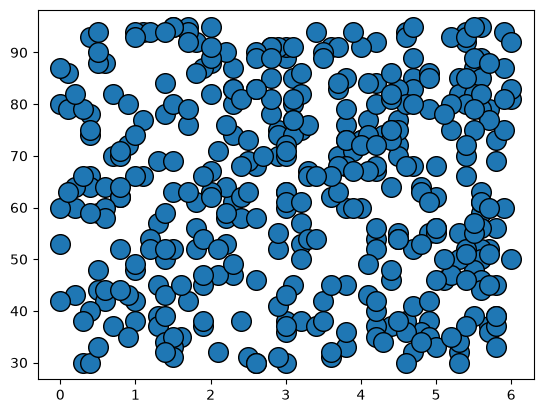

In [16]:
new_entry = pd.DataFrame({
    "study_hours" :[ 1],
    "attendance" : [60],
    "phone_hours" : [6.0],
    "past_mark" : [45]
})
colors = df["study_hours"].map({0: "tomato", 1:"seagreen"})
plt.scatter(df["study_hours"], df["past_mark"] , s=200, edgecolors = "black").itterows()
for name, row in df.itterows():
     plt.annotate(name, (row["study_hours"], row["past_mark"]), xytext=(0, 15), textcoords="offset points", ha="center")
plt.scatter(100, 8, marker="*", s=600, color="gold", edgecolors="black", label="NEW person")
plt.xlabel("Monthly income (thousand Rs)")
plt.ylabel("Years in job")
plt.title("8 applicants (green = approved, red = not approved)")
plt.legend()
plt.show()


# Key Takeaways

**Classification:** guesses a **group**. We check it with **accuracy** (right ÷ all). Always test on **hidden** data, and split with `stratify=y`.

**Part 1: Logistic Regression**
- Score $z = \beta_0 + \beta_1 x_1 + \dots$ (a line), then the **sigmoid** $\dfrac{1}{1 + e^{-z}}$ gives a **chance** from 0 to 1.
- Chance above 0.5 (z above 0) → yes.
- It does not need scaling.

**Part 2: KNN**
- Distance to every example → the **k nearest** → **vote**. Use an odd k.
- It **needs scaling**: $z = \dfrac{x - \text{mean}}{\text{std}}$, because the column with big numbers wins.
- **Fit the scaler on train only**, then transform train, test and new people.

**Both:** `fit()` learns (or remembers). `predict()` does the small calculation we did by hand. Compare models on the **same** test data.

**Next class:** Decision Trees, and why **accuracy can lie**.